# ArtFilters – Emma's Notebook

**Developer:** Emma Radojcic (C22369396)
**Module:** Image Processing
**Project:** ArtFilters – turning photos into artwork using classical computer vision
**Focus:** No AI or machine learning, just OpenCV and NumPy

## My Filters

- **Dreamy Glow** ✅ – soft glowing effect using a hand-built Gaussian kernel, highlight extraction and screen blending
- *More filters to be added as they're allocated each week*

---

## Filter 1: Dreamy Glow

Makes the bright parts of a photo bloom outwards with a soft glow. Uses a hand-built Gaussian kernel, highlight extraction, two blurs (small and large) and a screen blend.

**Settings:** `sigma` (glow spread), `threshold` (how bright to glow), `boost` (glow intensity), `strength` (overall amount)

### Setup

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# folders are relative to this notebook (which sits in the emma folder)
input_dir = "images/input"
output_dir = "images/output"
os.makedirs(output_dir, exist_ok=True)

print("setup done")

setup done


### Load Images

In [16]:
# get every image file in the input folder
file_names = sorted(os.listdir(input_dir))
images = [cv2.imread(os.path.join(input_dir, f)) for f in file_names]

# imread fails silently so check none of them came back empty
for name, img in zip(file_names, images):
    if img is None:
        print("couldnt load", name)
    else:
        print(name, img.shape)

Img1Art.jpg (2880, 2160, 3)
Img2Art.jpg (2880, 2160, 3)
Img3Art.jpg (2880, 2160, 3)
Img4Art.jpg (2880, 2160, 3)
Img5Art.jpg (2880, 2160, 3)


### Step 1: Build a Gaussian Kernel

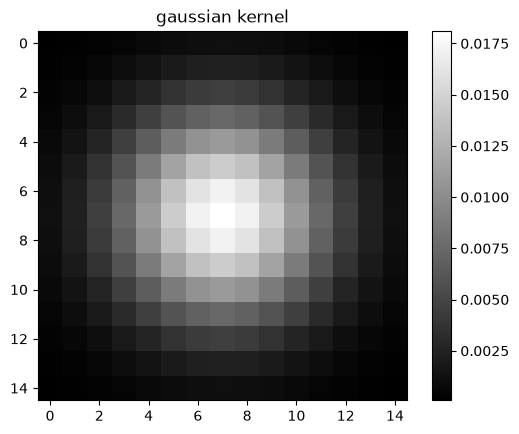

In [17]:
def make_gaussian_kernel(size, sigma):
    # kernel size has to be odd so there's a centre pixel
    if size % 2 == 0:
        size += 1

    # distances from the centre e.g. -2 -1 0 1 2
    half = size // 2
    x = np.arange(-half, half + 1)
    xx, yy = np.meshgrid(x, x)

    # gaussian formula - values drop off the further from the centre you go
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))

    # divide by the total so it adds up to 1 and brightness stays the same
    return kernel / kernel.sum()

# quick look at a small one to see the shape
k = make_gaussian_kernel(15, 3)
plt.imshow(k, cmap="gray")
plt.title("gaussian kernel")
plt.colorbar()
plt.show()

### Step 2: Test the Blur

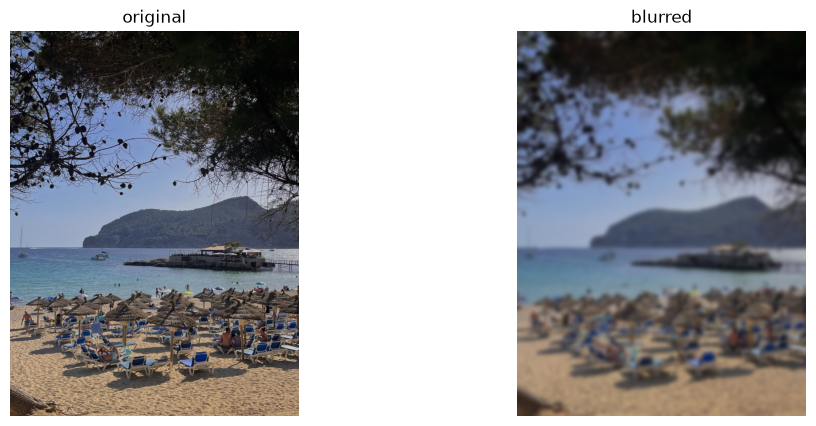

In [18]:
img = images[0]

# bigger sigma = softer blur, size around 6x sigma covers the whole bell curve
sigma = 15
kernel = make_gaussian_kernel(6 * sigma + 1, sigma)

# filter2D slides the kernel over every pixel (convolution) like in the lab
blurred = cv2.filter2D(img, -1, kernel, borderType=cv2.BORDER_REFLECT)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB))
plt.title("blurred")
plt.axis("off")
plt.show()

### Step 3: Screen Blend

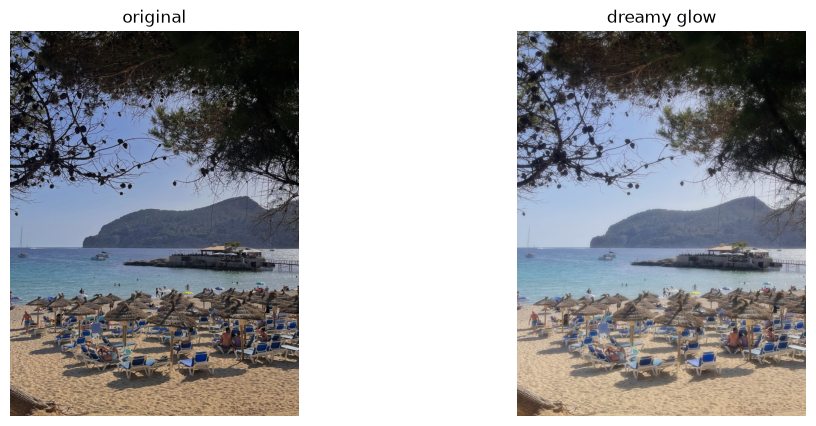

In [19]:
# convert to 0-1 floats so the maths works properly
a = img.astype(np.float32) / 255
b = blurred.astype(np.float32) / 255

# screen blend - brightens and makes the light areas bloom
screen = 1 - (1 - a) * (1 - b)

# mix the glow with the original, 0 = no glow 1 = full glow
strength = 0.6
glow = (1 - strength) * a + strength * screen

# back to normal 0-255 image
glow = np.clip(glow * 255, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(glow, cv2.COLOR_BGR2RGB))
plt.title("dreamy glow")
plt.axis("off")
plt.show()

### Dreamy Glow Filter

In [20]:
def dreamy_glow(image, sigma=20, strength=0.8, threshold=0.5, boost=1.5):
    # convert to 0-1 floats
    a = image.astype(np.float32) / 255

    # pick out just the bright parts
    # anything darker than the threshold gets ignored, brighter parts fade in
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255
    mask = np.clip((gray - threshold) / (1 - threshold), 0, 1)
    highlights = a * mask[:, :, np.newaxis]

    # two blurs - a tight glow around the light and a wide soft haze
    small_sigma = max(1, sigma // 3)
    small = cv2.filter2D(highlights, -1, make_gaussian_kernel(6 * small_sigma + 1, small_sigma), borderType=cv2.BORDER_REFLECT)
    big = cv2.filter2D(highlights, -1, make_gaussian_kernel(6 * sigma + 1, sigma), borderType=cv2.BORDER_REFLECT)

    # add the two together and boost so the glow is stronger
    glow_layer = np.clip((small + big) * boost, 0, 1)

    # screen blend the glow on top, strength controls how much
    result = 1 - (1 - a) * (1 - glow_layer * strength)

    return np.clip(result * 255, 0, 255).astype(np.uint8)

### Apply to All Images

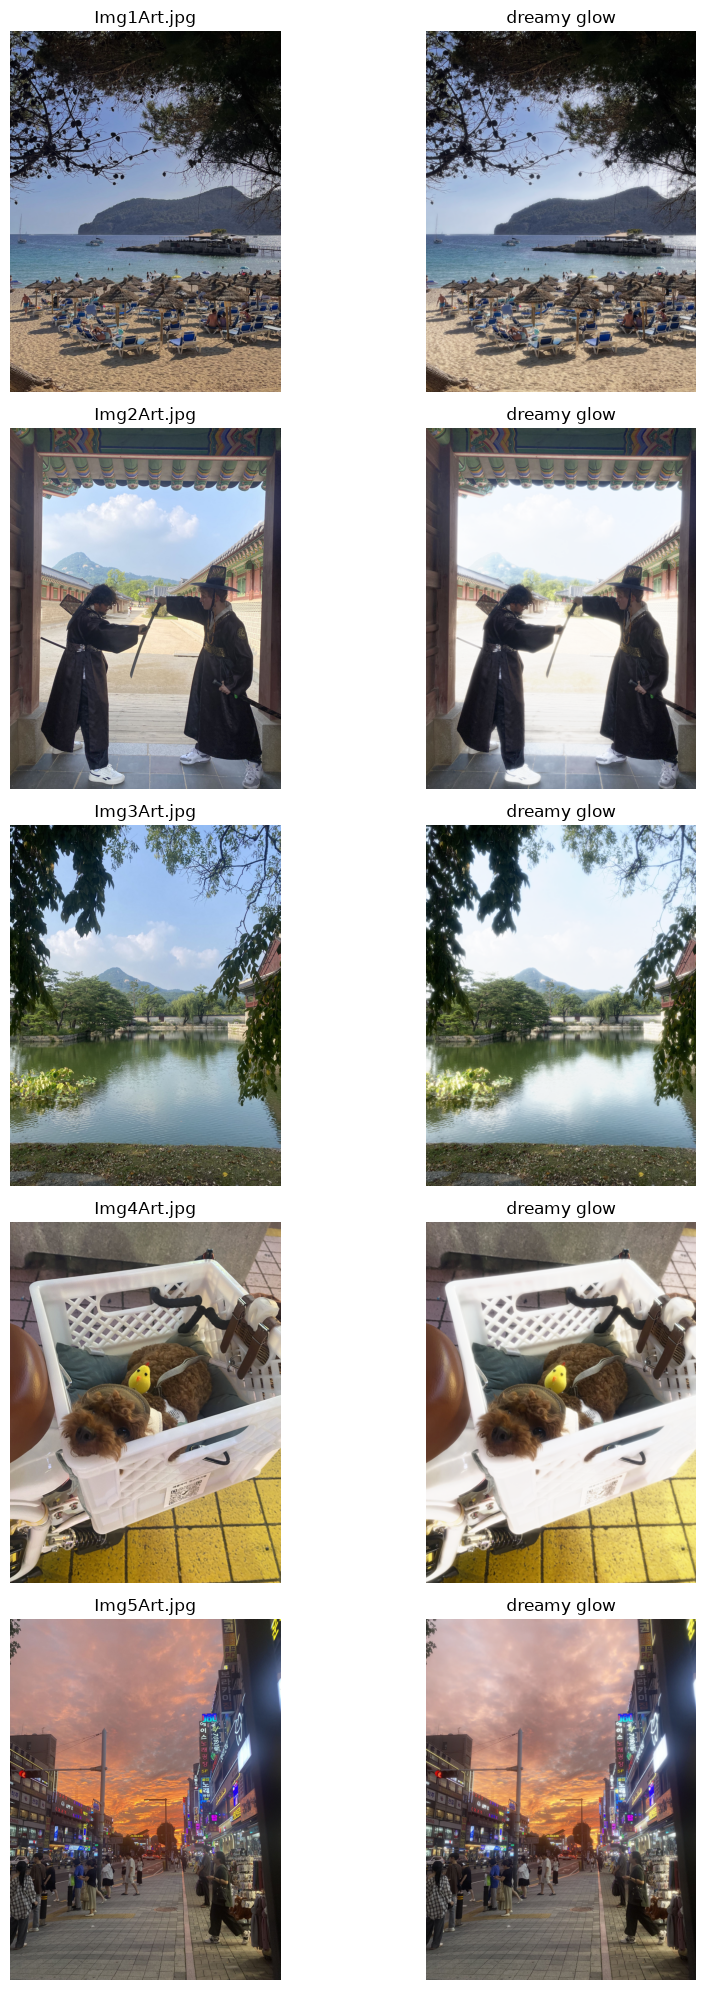

saved to images/output


In [21]:
results = [dreamy_glow(img) for img in images]

# before and after for every image
fig, axes = plt.subplots(len(images), 2, figsize=(10, 4 * len(images)))
for i in range(len(images)):
    axes[i][0].imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    axes[i][0].set_title(file_names[i])
    axes[i][0].axis("off")

    axes[i][1].imshow(cv2.cvtColor(results[i], cv2.COLOR_BGR2RGB))
    axes[i][1].set_title("dreamy glow")
    axes[i][1].axis("off")
plt.tight_layout()
plt.show()

# save the filtered versions into the output folder
for name, result in zip(file_names, results):
    cv2.imwrite(os.path.join(output_dir, "glow_" + name), result)

print("saved to", output_dir)